In [1]:
!pip install -q sentence-transformers

In [2]:
import json
import numpy as np

import pandas as pd

from tqdm import tqdm

from sentence_transformers import SentenceTransformer

from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt

from collections import Counter

In [3]:
INPUT_FILE="/content/drive/MyDrive/real_news_dataset_30k.json"

with open(INPUT_FILE,"r",encoding="utf8") as f:
    data=json.load(f)

articles=data["articles"]

print(len(articles))

30000


In [4]:
texts=[]

for article in articles:

    txt=article["title"]+" "+article["text"]

    texts.append(txt)

In [5]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

model = SentenceTransformer(
    "BAAI/bge-m3",
    device=device
)

Using device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [6]:
embeddings = model.encode(
    texts,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

print(type(embeddings))
print(embeddings.shape)

print()
print("Nombre d'articles :", len(texts))
print("Dimension embedding :", embeddings.shape[1])

Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

<class 'numpy.ndarray'>
(30000, 1024)

Nombre d'articles : 30000
Dimension embedding : 1024


## Pipeline Final : Extraction du Dataset Représentatif (10k)
Ce pipeline automatise la réduction de dimension et le clustering pour passer de 30k à 10k articles tout en préservant la diversité sémantique.

In [7]:
import time
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
from collections import Counter, defaultdict



# --- CONFIGURATION ---
N_CLUSTERS = 10000
PCA_COMPONENTS = 128
SEED = 42
OUTPUT_FILE = "Real_news_dataset_10k_final.json"

print(f"--- Démarrage du Pipeline d'Optimisation (KMeans Haute Performance) ---")
start_total = time.time()

# 1. Réduction de dimension (PCA)
print(f"1/4. Réduction PCA ({embeddings.shape[1]} -> {PCA_COMPONENTS})...")
pca = PCA(n_components=PCA_COMPONENTS,
          random_state=42)
embeddings_reduced = pca.fit_transform(embeddings)
print(f"   > Variance conservée : {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 2. Clustering KMeans Ultra-Accéléré
# algorithm='elkan' est plus rapide, tol=1e-3 et max_iter=50 pour accélérer la convergence
print(f"2/4. Clustering KMeans ({N_CLUSTERS} clusters, convergence rapide)...")


# ==========================================================
# KMEANS PAR CATÉGORIE
# ==========================================================

category_indices = defaultdict(list)

for i, article in enumerate(articles):
    category_indices[article["category"]].append(i)

category_counts = {
    category: len(indices)
    for category, indices in category_indices.items()
}

total_articles = len(articles)

# ----------------------------------------------------------
# Calcul des quotas proportionnels
# ----------------------------------------------------------

quotas = {}

for category, count in category_counts.items():

    proportion = count / total_articles

    quotas[category] = round(
        proportion * N_CLUSTERS
    )

# ----------------------------------------------------------
# Ajustement pour obtenir exactement 10 000
# ----------------------------------------------------------

difference = N_CLUSTERS - sum(quotas.values())

if difference != 0:

    biggest_category = max(
        quotas,
        key=quotas.get
    )

    quotas[biggest_category] += difference

print("\nQuotas KMeans par catégorie :\n")

for category in sorted(quotas):

    print(
        f"{category:15s} : "
        f"{category_counts[category]:5d} articles → "
        f"{quotas[category]:5d} clusters"
    )

print(
    "\nTotal clusters :",
    sum(quotas.values())
)




--- Démarrage du Pipeline d'Optimisation (KMeans Haute Performance) ---
1/4. Réduction PCA (1024 -> 128)...
   > Variance conservée : 67.29%
2/4. Clustering KMeans (10000 clusters, convergence rapide)...

Quotas KMeans par catégorie :

Business        :   484 articles →   161 clusters
Crime           :  2151 articles →   717 clusters
Economy         :  2279 articles →   760 clusters
Education       :  1628 articles →   543 clusters
Entertainment   :  1290 articles →   430 clusters
Environment     :   515 articles →   172 clusters
Health          :  4268 articles →  1423 clusters
Politics        : 13943 articles →  4646 clusters
Science         :   389 articles →   130 clusters
Sports          :  2802 articles →   934 clusters
Technology      :   251 articles →    84 clusters

Total clusters : 10000


In [8]:
representative_indices = []

for category, indices in category_indices.items():

    quota = quotas[category]

    X_category = embeddings_reduced[indices]

    print(
        f"\n{category}: "
        f"{len(indices)} articles → "
        f"{quota} représentants"
    )

    kmeans = KMeans(
        n_clusters=quota,
        random_state=SEED,
        n_init=1,
        algorithm="elkan",
        max_iter=50,
        tol=1e-3
    )

    kmeans.fit(X_category)

    # ------------------------------------------------------
    # Trouver l'article le plus proche de chaque centroïde
    # ------------------------------------------------------

    closest_indices, _ = pairwise_distances_argmin_min(
        kmeans.cluster_centers_,
        X_category
    )

    # Transformer les indices locaux en indices globaux
    for local_index in closest_indices:

        global_index = indices[local_index]

        representative_indices.append(
            global_index
        )


Environment: 515 articles → 172 représentants

Health: 4268 articles → 1423 représentants

Economy: 2279 articles → 760 représentants

Technology: 251 articles → 84 représentants

Education: 1628 articles → 543 représentants

Sports: 2802 articles → 934 représentants

Politics: 13943 articles → 4646 représentants

Science: 389 articles → 130 représentants

Crime: 2151 articles → 717 représentants

Business: 484 articles → 161 représentants

Entertainment: 1290 articles → 430 représentants


In [9]:
# Supprimer d'éventuels doublons
representative_indices = sorted(
    set(representative_indices)
)

new_articles_10k = [
    articles[i]
    for i in representative_indices
]

print("\n==========================================")
print("Sélection terminée")
print("==========================================")

print(
    "Articles initiaux :",
    len(articles)
)

print(
    "Articles finaux :",
    len(new_articles_10k)
)


Sélection terminée
Articles initiaux : 30000
Articles finaux : 10000


In [10]:


# 4. Sauvegarde
with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump({"articles": new_articles_10k}, f, ensure_ascii=False, indent=4)

print(f"4/4. Succès ! Dataset sauvegardé dans {OUTPUT_FILE}")
print(f"--- Temps total : {time.time() - start_total:.2f}s ---")



4/4. Succès ! Dataset sauvegardé dans Real_news_dataset_10k_final.json
--- Temps total : 82.66s ---


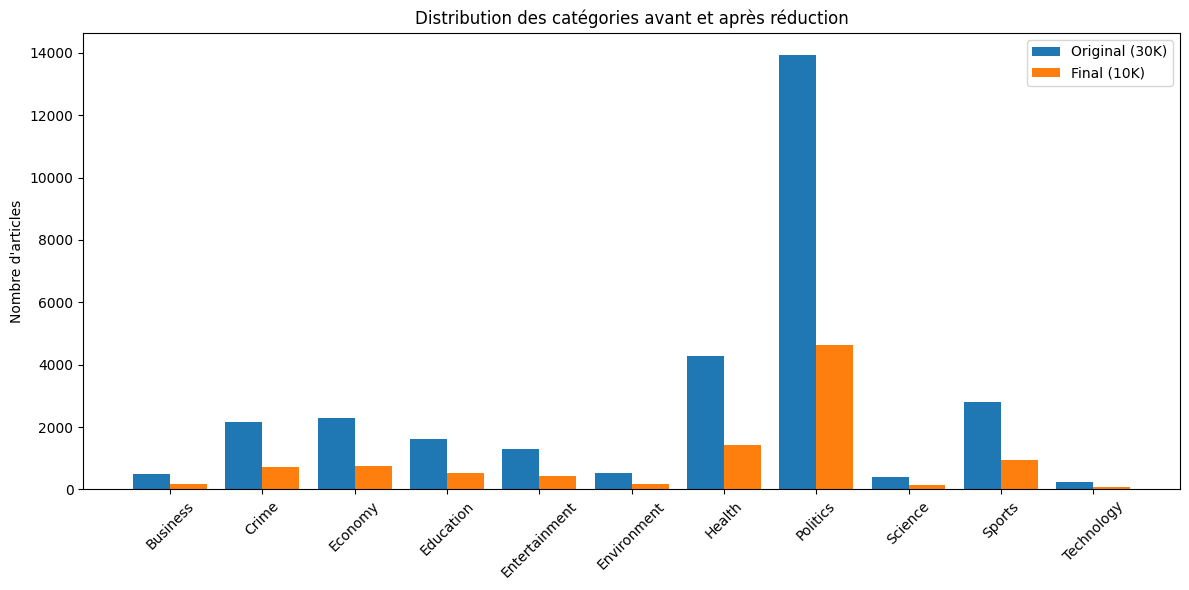

In [11]:
# --- VISUALISATION DE LA QUALITÉ ---
def plot_comparison(original, reduced):

    c_orig = Counter(
        article["category"]
        for article in original
    )

    c_red = Counter(
        article["category"]
        for article in reduced
    )

    categories = sorted(c_orig.keys())

    x = np.arange(len(categories))

    plt.figure(figsize=(12, 6))

    plt.bar(
        x - 0.2,
        [c_orig[c] for c in categories],
        0.4,
        label="Original (30K)"
    )

    plt.bar(
        x + 0.2,
        [c_red[c] for c in categories],
        0.4,
        label="Final (10K)"
    )

    plt.xticks(
        x,
        categories,
        rotation=45
    )

    plt.ylabel("Nombre d'articles")

    plt.title(
        "Distribution des catégories avant et après réduction"
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


plot_comparison(
    articles,
    new_articles_10k
)

In [12]:
print("="*80)

print("Résumé")

print("="*80)

print("Articles initiaux :",len(articles))

print("Articles finaux :",len(new_articles_10k))

print("Réduction :",100*(1-len(new_articles_10k)/len(articles)),"%")

print("Catégories :",len(Counter(a["category"] for a in new_articles_10k)))

print("Temps total :",time.time()-start_total,"secondes")

Résumé
Articles initiaux : 30000
Articles finaux : 10000
Réduction : 66.66666666666667 %
Catégories : 11
Temps total : 82.98927044868469 secondes


In [13]:
before = Counter(
    a["category"]
    for a in articles
)

after = Counter(
    a["category"]
    for a in new_articles_10k
)

for c in sorted(before):

    p1 = before[c] / len(articles) * 100

    p2 = after[c] / len(new_articles_10k) * 100

    print(
        f"{c:15s} "
        f"{p1:.2f}% -> {p2:.2f}%"
    )

Business        1.61% -> 1.61%
Crime           7.17% -> 7.17%
Economy         7.60% -> 7.60%
Education       5.43% -> 5.43%
Entertainment   4.30% -> 4.30%
Environment     1.72% -> 1.72%
Health          14.23% -> 14.23%
Politics        46.48% -> 46.46%
Science         1.30% -> 1.30%
Sports          9.34% -> 9.34%
Technology      0.84% -> 0.84%


In [14]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

selected_embeddings = embeddings[
    representative_indices
]

# ----------------------------------------------------------
# Recherche du voisin le plus proche
# ----------------------------------------------------------

nn = NearestNeighbors(
    n_neighbors=2,
    metric="cosine",
    n_jobs=-1
)

nn.fit(selected_embeddings)

distances, indices_nn = nn.kneighbors(
    selected_embeddings
)

# Le premier voisin est l'article lui-même
nearest_distances = distances[:, 1]

nearest_similarities = 1 - nearest_distances

print("\n==========================================")
print("Analyse de similarité")
print("==========================================")

print(
    "Similarité moyenne du voisin le plus proche :",
    nearest_similarities.mean()
)

print(
    "Similarité médiane :",
    np.median(nearest_similarities)
)

print(
    "Similarité maximale :",
    nearest_similarities.max()
)

print(
    "95e percentile :",
    np.percentile(nearest_similarities, 95)
)

print(
    "Paires avec similarité > 0.90 :",
    np.sum(nearest_similarities > 0.90)
)

print(
    "Paires avec similarité > 0.95 :",
    np.sum(nearest_similarities > 0.95)
)


Analyse de similarité
Similarité moyenne du voisin le plus proche : 0.64389354
Similarité médiane : 0.63390857
Similarité maximale : 0.9538927
95e percentile : 0.79279375
Paires avec similarité > 0.90 : 42
Paires avec similarité > 0.95 : 4
